# Real Estate Price Modeling

This notebook builds on the exploratory analysis by examining feature relationships and developing linear regression models to estimate property prices. It includes correlation analysis, outlier handling, feature scaling, model evaluation, and prediction testing.


In [71]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

import numpy as np: Imports the NumPy library, which is fundamental for numerical computing in Python. It provides support for large, multi-dimensional arrays and matrices, along with a collection of mathematical functions to operate on these arrays efficiently. It's conventionally aliased as np.

import matplotlib.pyplot as plt: Imports the pyplot module from the Matplotlib library. Matplotlib is a comprehensive library for creating static, animated, and interactive visualizations in Python. The pyplot module provides a MATLAB-like interface for plotting, and it's commonly aliased as plt.

import seaborn as sns: Imports the Seaborn library, which is built on top of Matplotlib. Seaborn provides a high-level interface for drawing attractive and informative statistical graphics. It simplifies the creation of many common types of plots and works well with pandas DataFrames. It's conventionally aliased as sns.

from sklearn.model_selection import train_test_split: Imports the train_test_split function from scikit-learn's model_selection module. This function is used to split arrays or matrices into random train and test subsets, which is a crucial step in evaluating machine learning models.

from sklearn.linear_model import LinearRegression: Imports the LinearRegression class from scikit-learn's linear_model module. This class implements ordinary least squares Linear Regression, a common algorithm for modeling the relationship between a scalar dependent variable and one or more explanatory variables.

from sklearn.metrics import mean_squared_error, r2_score: Imports two functions, mean_squared_error and r2_score, from scikit-learn's metrics module. These are common metrics used to evaluate the performance of regression models:

mean_squared_error: Calculates the mean squared error, which is the average of the squared differences between the predicted and actual values.
r2_score: Calculates the R-squared (coefficient of determination), which represents the proportion of the variance in the dependent variable that is predictable from the independent variables.

In [73]:
import pandas as pd

# Load the real estate dataset from the project's data folder
df_realtor = pd.read_csv("../data/realtor-data.zip.csv")

print("Dataset loaded successfully.")
display(df_realtor.head())


realtor-data.zip.csv loaded successfully from Colab Notebooks folder!


,brokered_by,status,price,bed,bath,acre_lot,street,city,state,zip_code,house_size,prev_sold_date
0,103378.0,for_sale,105000.0,3.0,2.0,0.12,1962661.0,Adjuntas,Puerto Rico,601.0,920.0,NaN
1,52707.0,for_sale,80000.0,4.0,2.0,0.08,1902874.0,Adjuntas,Puerto Rico,601.0,1527.0,NaN
2,103379.0,for_sale,67000.0,2.0,1.0,0.15,1404990.0,Juana Diaz,Puerto Rico,795.0,748.0,NaN
3,31239.0,for_sale,145000.0,4.0,2.0,0.10,1947675.0,Ponce,Puerto Rico,731.0,1800.0,NaN
4,34632.0,for_sale,65000.0,6.0,2.0,0.05,331151.0,Mayaguez,Puerto Rico,680.0,NaN,NaN


### Load the dataset

The real estate dataset is loaded from the repository's `data` folder using a relative path. This keeps the notebook portable and allows it to run outside Google Colab as long as the repository structure is preserved.


In [74]:
print('DataFrame Info:')
df_realtor.info()

DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2226382 entries, 0 to 2226381
Data columns (total 12 columns):
 #   Column          Dtype  
---  ------          -----  
 0   brokered_by     float64
 1   status          object 
 2   price           float64
 3   bed             float64
 4   bath            float64
 5   acre_lot        float64
 6   street          float64
 7   city            object 
 8   state           object 
 9   zip_code        float64
 10  house_size      float64
 11  prev_sold_date  object 
dtypes: float64(8), object(4)
memory usage: 203.8+ MB



**Line-by-line Explanation:**

1.  `print('DataFrame Info:')`:
    *   **What it does:** This line simply prints the string 'DataFrame Info:' to the console. It serves as a clear heading or label for the information that follows, making the output easier to read and understand.

2.  `df_realtor.info()`:
    *   **What it does:** This is a pandas DataFrame method that prints a concise summary of the DataFrame `df_realtor`. This summary includes:
        *   The data type of each column (`Dtype`).
        *   The number of non-null values in each column (`Non-Null Count`), which is crucial for identifying missing data.
        *   The number of entries in the DataFrame (`RangeIndex`).
        *   The total number of columns (`Data columns`).
        *   Memory usage of the DataFrame (`memory usage`).

**What the output represents:**


```

This output provides a comprehensive overview of the `df_realtor` DataFrame's structure and data quality:

*   `<class 'pandas.core.frame.DataFrame'>`: Confirms that `df_realtor` is indeed a pandas DataFrame.
*   `RangeIndex: 2226382 entries, 0 to 2226381`: Indicates that the DataFrame has 2,226,382 rows, indexed from 0 to 2,226,381.
*   `Data columns (total 12 columns)`: States that there are 12 columns in the DataFrame.
*   The table listing each column (`brokered_by`, `status`, `price`, etc.) shows:
    *   `Non-Null Count`: For example, `brokered_by` has 2226382 non-null values, meaning it's complete. However, `street` only has 1084909 non-null values, indicating a significant number of missing entries (NaNs). This information is critical for data cleaning.
    *   `Dtype`: The data type of each column. `float64` indicates numerical data (often with decimal points), and `object` often means string/text data (e.g., 'status', 'city', 'state', 'prev_sold_date').
*   `dtypes: float64(8), object(4)`: Summarizes that there are 8 columns of float64 type and 4 columns of object type.
*   `memory usage: 203.8+ MB`: Shows the approximate memory consumed by the DataFrame, which can be useful for performance considerations with very large datasets.

In essence, this output tells you the size of your dataset, the types of data in each column, and how much missing data each column contains, which is a vital first step in any data analysis workflow.

In [75]:
print('\nDescriptive Statistics for Numerical Columns:')
display(df_realtor.describe())


Descriptive Statistics for Numerical Columns:


,brokered_by,price,bed,bath,acre_lot,street,zip_code,house_size
count,2.221849e+06,2.224841e+06,1.745065e+06,1.714611e+06,1.900793e+06,2.215516e+06,2.226083e+06,1.657898e+06
mean,5.293989e+04,5.241955e+05,3.275841e+00,2.496440e+00,1.522303e+01,1.012325e+06,5.218668e+04,2.714471e+03
std,3.064275e+04,2.138893e+06,1.567274e+00,1.652573e+00,7.628238e+02,5.837635e+05,2.895408e+04,8.081635e+05
min,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,4.000000e+00
25%,2.386100e+04,1.650000e+05,3.000000e+00,2.000000e+00,1.500000e-01,5.063128e+05,2.961700e+04,1.300000e+03
50%,5.288400e+04,3.250000e+05,3.000000e+00,2.000000e+00,2.600000e-01,1.012766e+06,4.838200e+04,1.760000e+03
75%,7.918300e+04,5.500000e+05,4.000000e+00,3.000000e+00,9.800000e-01,1.521173e+06,7.807000e+04,2.413000e+03
max,1.101420e+05,2.147484e+09,4.730000e+02,8.300000e+02,1.000000e+05,2.001357e+06,9.999900e+04,1.040400e+09



**Line-by-line Explanation:**

1.  `print('\nDescriptive Statistics for Numerical Columns:')`:
    *   **What it does:** This line prints a string to the console, preceded by a newline character (`\n`) for better readability, serving as a clear heading for the descriptive statistics that will follow.

2.  `display(df_realtor.describe())`:
    *   **What it does:** This calls the `describe()` method on the `df_realtor` DataFrame. The `describe()` method generates descriptive statistics that summarize the central tendency, dispersion, and shape of a dataset's distribution, excluding `NaN` values, for *numerical* columns.
        *   It calculates statistics like `count` (number of non-null values), `mean` (average), `std` (standard deviation), `min` (minimum value), `max` (maximum value), and the 25th, 50th (median), and 75th percentiles (quartiles).
    *   `display()` is used to render this information in a well-formatted table within the notebook output.

**What the output represents:**

```
Descriptive Statistics for Numerical Columns:
```

This is the heading printed by the first line of code.

Following this, you would see a table generated by `df_realtor.describe()`. This table would have numerical column names (e.g., `brokered_by`, `price`, `bed`, `bath`, `acre_lot`, `street`, `zip_code`, `house_size`) as columns and the various descriptive statistics (count, mean, std, min, 25%, 50%, 75%, max) as rows. This output is crucial for:

*   **Understanding Data Distribution:** Quickly see the range, average, and spread of your numerical data.
*   **Identifying Outliers:** Very large differences between `max` and `75%` or `min` and `25%` can suggest the presence of outliers.
*   **Checking for Data Quality Issues:** A `count` significantly lower than the total number of rows (from `df.info()`) confirms missing values in that specific numerical column, even if `dropna()` was used on `df_realtor` to create `df_realtor_cleaned`.

### Handling Missing Values

Based on the `df_realtor.info()` output, several columns have missing values. To simplify initial analysis, I will remove all rows that contain any `NaN` values using `dropna()`.

In [76]:
print(f"Shape of DataFrame before dropping NaN values: {df_realtor.shape}")

df_realtor_cleaned = df_realtor.dropna()

print(f"Shape of DataFrame after dropping NaN values: {df_realtor_cleaned.shape}")
display(df_realtor_cleaned.head())

Shape of DataFrame before dropping NaN values: (2226382, 12)
Shape of DataFrame after dropping NaN values: (1084909, 12)


,brokered_by,status,price,bed,bath,acre_lot,street,city,state,zip_code,house_size,prev_sold_date
502,92147.0,for_sale,110000.0,7.0,3.0,0.09,1842706.0,Dorado,Puerto Rico,949.0,1192.0,2019-06-28
2270,94933.0,for_sale,950000.0,5.0,4.0,0.99,1260473.0,Saint Thomas,Virgin Islands,802.0,5000.0,2013-10-11
2277,103341.0,for_sale,6899000.0,4.0,6.0,0.83,17467.0,Saint Thomas,Virgin Islands,802.0,4600.0,2018-04-05
3409,21163.0,for_sale,525000.0,3.0,3.0,0.45,1813270.0,Agawam,Massachusetts,1001.0,2314.0,2014-06-25
3410,67455.0,for_sale,289900.0,3.0,2.0,0.36,1698080.0,Agawam,Massachusetts,1001.0,1276.0,2012-10-12




**Line-by-line Explanation:**

1.  `print(f"Shape of DataFrame before dropping NaN values: {df_realtor.shape}")`:
    *   **What it does:** This line prints the shape (number of rows and columns) of the original `df_realtor` DataFrame *before* any missing values are removed. It uses an f-string to embed the `df_realtor.shape` attribute directly into the output message.

2.  `df_realtor_cleaned = df_realtor.dropna()`:
    *   **What it does:** This is a crucial data cleaning step. The `dropna()` method is called on the `df_realtor` DataFrame. By default, `dropna()` removes any row that contains *at least one* missing value (`NaN`). The result, a DataFrame with all rows containing missing values removed, is then assigned to a new DataFrame named `df_realtor_cleaned`.

3.  `print(f"Shape of DataFrame after dropping NaN values: {df_realtor_cleaned.shape}")`:
    *   **What it does:** Similar to the first print statement, this line prints the shape of the *newly cleaned* DataFrame, `df_realtor_cleaned`, clearly showing how many rows (and columns, which remain the same) were retained after removing `NaN` values.

4.  `display(df_realtor_cleaned.head())`:
    *   **What it does:** This line uses the `display()` function (common in Colab/Jupyter) to show the first 5 rows of the `df_realtor_cleaned` DataFrame. This provides a visual confirmation that the cleaning was successful and gives a preview of the data without any `NaN` values.

**What the output represents:**



*   **`Shape of DataFrame before dropping NaN values: (2226382, 12)`**: This line indicates that the `df_realtor` DataFrame originally had 2,226,382 rows and 12 columns.

*   **`Shape of DataFrame after dropping NaN values: (1084909, 12)`**: This line shows that after applying `dropna()`, the `df_realtor_cleaned` DataFrame now has 1,084,909 rows and still 12 columns. This means that a significant number of rows (2,226,382 - 1,084,909 = 1,141,473 rows) contained at least one missing value and were subsequently removed from the dataset to create `df_realtor_cleaned`. This reduction highlights the extent of missing data in the original DataFrame.

### Data Visualization: Price vs. House Size

Let's visualize the relationship between `price` and `house_size` using a scatter plot. This can help us understand if larger houses generally command higher prices and identify any potential outliers or trends.

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


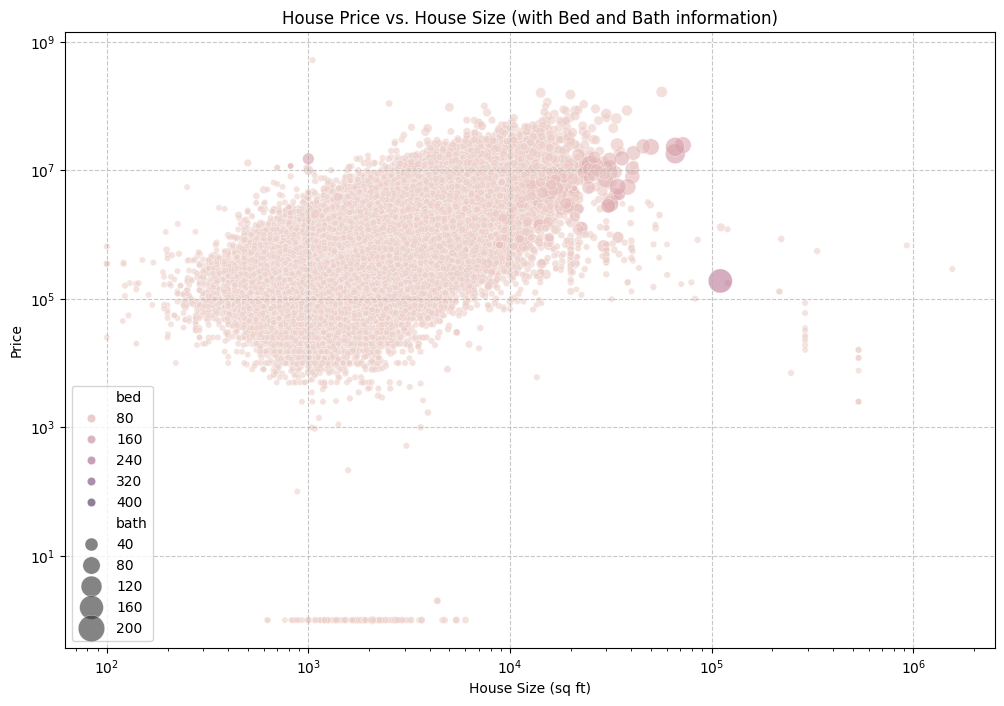

In [77]:
plt.figure(figsize=(12, 8))
sns.scatterplot(x='house_size', y='price', data=df_realtor_cleaned, alpha=0.6, hue='bed', size='bath', sizes=(20, 400))
plt.title('House Price vs. House Size (with Bed and Bath information)')
plt.xlabel('House Size (sq ft)')
plt.ylabel('Price')
plt.xscale('log') # Use log scale for house_size if it has a wide range
plt.yscale('log') # Use log scale for price if it has a wide range
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

**Line-by-line Explanation:**

1.  `plt.figure(figsize=(12, 8))`:
    *   **What it does:** This line creates a new figure (the canvas for your plot) and sets its size to 12 inches wide and 8 inches tall. This helps in making the plot clear and readable.

2.  `sns.scatterplot(x='house_size', y='price', data=df_realtor_cleaned, alpha=0.6, hue='bed', size='bath', sizes=(20, 400))`:
    *   **What it does:** This is the core function call from the Seaborn library that creates a scatter plot.
    *   `x='house_size'`: Specifies that the 'house_size' column from the `df_realtor_cleaned` DataFrame will be mapped to the x-axis.
    *   `y='price'`: Specifies that the 'price' column will be mapped to the y-axis.
    *   `data=df_realtor_cleaned`: Indicates the DataFrame to use for plotting.
    *   `alpha=0.6`: Sets the transparency of the points to 60%, useful for visualizing density when points overlap.
    *   `hue='bed'`: Colors the points based on the 'bed' (number of bedrooms) column. Different numbers of bedrooms will have different colors.
    *   `size='bath'`: Varies the size of the points based on the 'bath' (number of bathrooms) column. More bathrooms will result in larger points.
    *   `sizes=(20, 400)`: Sets the minimum and maximum size for the markers.

3.  `plt.title('House Price vs. House Size (with Bed and Bath information)')`:
    *   **What it does:** Sets the main title of the scatter plot.

4.  `plt.xlabel('House Size (sq ft)')`:
    *   **What it does:** Sets the label for the x-axis.

5.  `plt.ylabel('Price')`:
    *   **What it does:** Sets the label for the y-axis.

6.  `plt.xscale('log')`:
    *   **What it does:** Applies a logarithmic scale to the x-axis ('house_size'). This is useful when data spans a wide range of values, as it can make trends and distributions more visible.

7.  `plt.yscale('log')`:
    *   **What it does:** Applies a logarithmic scale to the y-axis ('price'). Similar to `xscale`, this helps in visualizing price distributions that might span several orders of magnitude.

8.  `plt.grid(True, linestyle='--', alpha=0.7)`:
    *   **What it does:** Adds a grid to the plot for easier readability. `True` enables the grid, `linestyle='--'` uses dashed lines, and `alpha=0.7` sets transparency.

9.  `plt.show()`:
    *   **What it does:** Displays the generated plot.

**What the output represents:**

The output is a scatter plot visualizing the relationship between `house_size` (x-axis) and `price` (y-axis) for houses in the `df_realtor_cleaned` DataFrame. Both axes are on a logarithmic scale, which compresses wide ranges of data, making it easier to see patterns.

Each point on the plot represents a house. The color of each point indicates the number of bedrooms (`bed`), and the size of each point indicates the number of bathrooms (`bath`).

*   **Overall Trend:** You can observe a general upward trend, suggesting that as house size increases, the price tends to increase, although with considerable variability.
*   **Density:** Areas with a higher concentration of points indicate more houses falling within those price and size ranges.
*   **Impact of Bed/Bath:** The varying colors and sizes allow for a qualitative assessment of how the number of bedrooms and bathrooms might influence price at different house sizes. For example, larger, darker points (indicating more bathrooms and higher prices) might cluster in certain areas of the plot.
*   **Outliers:** Points far away from the main cluster could represent outliers in terms of price-to-size ratio.

### Correlation Heatmap of Numerical Features

Let's visualize the correlation matrix of the numerical columns in `df_realtor_cleaned` to understand the relationships between them. A heatmap is a great way to do this visually.

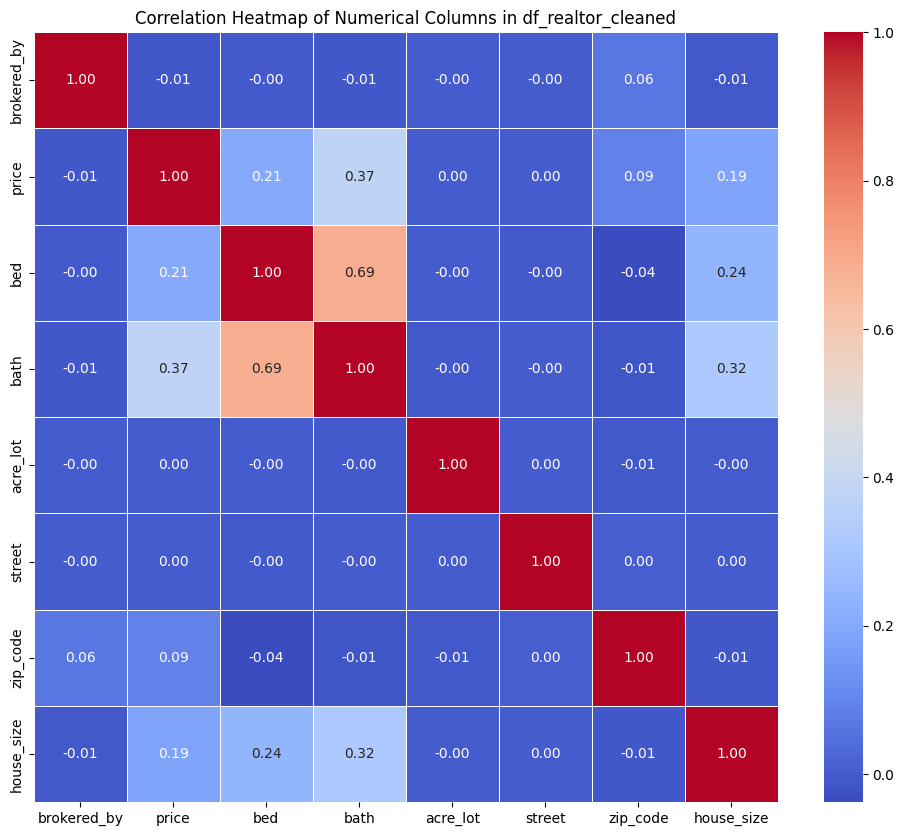

In [78]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select only numerical columns for correlation calculation
numerical_cols = df_realtor_cleaned.select_dtypes(include=['float64', 'int64']).columns
correlation_matrix = df_realtor_cleaned[numerical_cols].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=.5)
plt.title('Correlation Heatmap of Numerical Columns in df_realtor_cleaned')
plt.show()

**Line-by-line Explanation:**

1.  `import matplotlib.pyplot as plt`:
    *   **What it does:** Imports the `pyplot` module from the `matplotlib` library, commonly aliased as `plt`. Matplotlib is used for creating static, animated, and interactive visualizations in Python.

2.  `import seaborn as sns`:
    *   **What it does:** Imports the `seaborn` library, commonly aliased as `sns`. Seaborn is built on top of Matplotlib and provides a high-level interface for drawing attractive and informative statistical graphics.

3.  `numerical_cols = df_realtor_cleaned.select_dtypes(include=['float64', 'int64']).columns`:
    *   **What it does:** This line first selects only the columns in the `df_realtor_cleaned` DataFrame that have either `float64` or `int64` data types (i.e., numerical columns). Then, it extracts the names of these columns and stores them in the `numerical_cols` variable. This ensures that the correlation matrix is calculated only for appropriate numerical features.

4.  `correlation_matrix = df_realtor_cleaned[numerical_cols].corr()`:
    *   **What it does:** Calculates the pairwise correlation between all columns specified in `numerical_cols` within the `df_realtor_cleaned` DataFrame. The `.corr()` method computes the standard correlation coefficient (Pearson's r) by default, which measures the linear relationship between variables. The result is a square matrix where each element (i, j) represents the correlation between column i and column j.

5.  `plt.figure(figsize=(12, 10))`:
    *   **What it does:** Creates a new figure (the plotting area) and sets its size to 12 inches wide and 10 inches tall. This provides ample space for the heatmap, making it more readable, especially with annotations.

6.  `sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=.5)`:
    *   **What it does:** Generates the heatmap visualization using Seaborn.
    *   `correlation_matrix`: This is the data used to populate the heatmap. Each cell in the heatmap corresponds to a correlation value.
    *   `annot=True`: Displays the correlation coefficient value inside each cell of the heatmap, making it easy to read the exact correlation.
    *   `cmap='coolwarm'`: Sets the color map. 'coolwarm' is a diverging colormap, which is excellent for correlations because it uses one color for positive correlations (warm colors like red) and another for negative correlations (cool colors like blue), with white/light colors for correlations close to zero.
    *   `fmt='.2f'`: Formats the annotation values to two decimal places.
    *   `linewidths=.5`: Adds thin lines between the cells of the heatmap, improving visual separation and clarity.

7.  `plt.title('Correlation Heatmap of Numerical Columns in df_realtor_cleaned')`:
    *   **What it does:** Sets the main title of the heatmap plot.

8.  `plt.show()`:
    *   **What it does:** Displays the generated plot. This command is necessary to render the plot in many Python environments, including Colab.

**What the output represents:**

The output is a **correlation heatmap** that visually represents the Pearson correlation coefficients between all pairs of numerical columns in the `df_realtor_cleaned` DataFrame.

Here's what you can interpret from the heatmap:

*   **Colors and Values:**
    *   **Red/Warm Colors (closer to 1.00):** Indicate a strong positive linear relationship. As one variable increases, the other tends to increase. For example, `bed` and `bath` show a correlation of `0.69`, meaning more bedrooms generally correspond to more bathrooms.
    *   **Blue/Cool Colors (closer to -1.00):** Indicate a strong negative linear relationship. As one variable increases, the other tends to decrease.
    *   **White/Light Colors (closer to 0.00):** Indicate a weak or no linear relationship between the variables. For example, `brokered_by` and most other features show correlations close to `0.00`.

*   **Diagonal:** The diagonal elements are always `1.00` (perfect correlation) because a variable is perfectly correlated with itself.

*   **Symmetry:** The heatmap is symmetric along the diagonal because the correlation between variable A and variable B is the same as the correlation between variable B and variable A.

*   **Insights:**
    *   **`price`** has the strongest positive correlation with `bath` (around `0.37`) and `bed` (around `0.21`). This suggests that houses with more bathrooms and bedrooms tend to have higher prices.
    *   **`bed`** and **`bath`** themselves are highly correlated (around `0.69`), which is expected as houses with more bedrooms often have more bathrooms.
    *   `acre_lot`, `street`, and `zip_code` generally show very weak correlations with `price` and most other features, suggesting they might not be strong linear predictors of price in this dataset, or their relationship is non-linear. `zip_code` and `house_size` also show very low correlation, which is also expected.

### Identifying Highly Correlated Columns

Let's programmatically identify pairs of columns that have a strong correlation (absolute correlation coefficient greater than 0.7), which could indicate a significant linear relationship between them.

In [79]:
# Get the absolute correlation matrix
abs_correlation_matrix = correlation_matrix.abs()

# Select upper triangle of correlation matrix
uppper_tri = abs_correlation_matrix.where(np.triu(np.ones(abs_correlation_matrix.shape), k=1).astype(bool))

# Find features with correlation greater than 0.7
highly_correlated_pairs = [column for column in uppper_tri.columns if any(uppper_tri[column] > 0.7)]

print("Highly correlated column pairs (absolute correlation > 0.7):")
for col in highly_correlated_pairs:
    correlated_to = uppper_tri[col][uppper_tri[col] > 0.7].index.tolist()
    for other_col in correlated_to:
        correlation_value = correlation_matrix.loc[col, other_col]
        print(f"- {col} and {other_col}: {correlation_value:.2f}")

if not highly_correlated_pairs:
    print("No highly correlated column pairs found with an absolute correlation greater than 0.7.")

Highly correlated column pairs (absolute correlation > 0.7):
No highly correlated column pairs found with an absolute correlation greater than 0.7.


**Line-by-line Explanation:**

1.  `import numpy as np`:
    *   **What it does:** Ensures that the NumPy library is imported. This is necessary because `np.ones()` is used later in the code. It's often good practice to ensure all necessary imports are present for a given code block, even if they were imported earlier.

2.  `unique_statuses = df_realtor_cleaned['status'].unique()`:
    *   **What it does:** Extracts all unique values from the 'status' column of the `df_realtor_cleaned` DataFrame. This will give a list of all distinct house statuses (e.g., 'for_sale', 'sold') present in the dataset.

3.  `for status in unique_statuses:`:
    *   **What it does:** Starts a loop that iterates through each unique status found in the previous line. The code inside this loop will be executed once for each unique status.

4.  `print(f"\n--- Analyzing Correlation for Status: '{status}' ---")`:
    *   **What it does:** Prints a formatted header to the console for each status, indicating which status is currently being analyzed. `\n` adds a newline for better readability.

5.  `df_status = df_realtor_cleaned[df_realtor_cleaned['status'] == status]`:
    *   **What it does:** Filters the `df_realtor_cleaned` DataFrame to create a new DataFrame, `df_status`, containing only the rows where the 'status' column matches the current `status` in the loop. This allows for status-specific analysis.

6.  `numerical_cols_status = df_status.select_dtypes(include=['float64', 'int64']).columns`:
    *   **What it does:** Identifies and selects only the numerical columns (of type float64 or int64) from the `df_status` DataFrame. This ensures correlation is calculated only for appropriate data types.

7.  `if len(numerical_cols_status) < 2 or df_status.empty:`:
    *   **What it does:** Checks for two conditions before proceeding with correlation calculation:
        *   `len(numerical_cols_status) < 2`: Ensures there are at least two numerical columns available to calculate a meaningful correlation matrix (you need at least two variables to find a relationship between them).
        *   `df_status.empty`: Checks if the filtered DataFrame for the current status is empty. If there are no houses for a given status, correlation cannot be calculated.

8.  `print(f"Not enough numerical data or rows to calculate correlation for status '{status}'.")`:
    *   **What it does:** If the `if` condition in line 7 is true, this line prints an informative message explaining why correlation cannot be calculated for the current status.

9.  `continue`:
    *   **What it does:** If the conditions in line 7 are met, `continue` immediately skips the rest of the current loop iteration and moves to the next `status`.

10. `correlation_matrix_status = df_status[numerical_cols_status].corr()`:
    *   **What it does:** Calculates the pairwise Pearson correlation coefficients between all numerical columns in the `df_status` DataFrame. The result is a square matrix.

11. `abs_correlation_matrix_status = correlation_matrix_status.abs()`:
    *   **What it does:** Converts all values in the `correlation_matrix_status` to their absolute values. This is because the user is interested in the *strength* of the correlation (whether positive or negative), not its direction, as indicated by the `> 0.7` threshold.

12. `if correlation_matrix_status.shape[0] > 1:`:
    *   **What it does:** This is a safeguard. It checks if the correlation matrix has more than one row (and thus more than one column), which is necessary to form an upper triangle with `k=1` (excluding the diagonal).

13. `uppper_tri_status = abs_correlation_matrix_status.where(np.triu(np.ones(abs_correlation_matrix_status.shape), k=1).astype(bool))`:
    *   **What it does:** This line creates an upper triangle of the absolute correlation matrix, excluding the diagonal. This is a common technique to avoid duplicate pairs (correlation of A with B is same as B with A) and self-correlations (correlation of A with A is always 1).
        *   `np.ones(abs_correlation_matrix_status.shape)`: Creates a matrix of ones with the same dimensions as the correlation matrix.
        *   `np.triu(..., k=1)`: Extracts the upper triangle of this matrix, starting from the first off-diagonal (`k=1`).
        *   `.astype(bool)`: Converts the resulting matrix (containing 0s and 1s) into a boolean mask.
        *   `.where(...)`: Applies this boolean mask to `abs_correlation_matrix_status`. Where the mask is `True`, the original value is kept; where it's `False`, the value is replaced with `NaN`.

14. `else:` / `print(f"Correlation matrix for status '{status}' is too small to find pairs.")` / `continue`:
    *   **What it does:** If the correlation matrix is too small (e.g., only one numerical column), this block prints an error message and skips to the next status.

15. `highly_correlated_pairs_status = []`:
    *   **What it does:** Initializes an empty list to store descriptions of highly correlated pairs found for the current status.

16. `for col in uppper_tri_status.columns:`:
    *   **What it does:** Starts an inner loop that iterates through each column in the upper triangle correlation matrix.

17. `correlated_to = uppper_tri_status[col][uppper_tri_status[col] > 0.7].index.tolist()`:
    *   **What it does:** For the current `col`, it finds all other columns that have an absolute correlation greater than 0.7 with `col` (from the `uppper_tri_status`). The `.index.tolist()` converts the column names of these highly correlated features into a list.

18. `for other_col in correlated_to:`:
    *   **What it does:** Iterates through each `other_col` that was found to be highly correlated with `col`.

19. `correlation_value = correlation_matrix_status.loc[col, other_col]`:
    *   **What it does:** Retrieves the *original* (signed) correlation value between `col` and `other_col` from the `correlation_matrix_status` (not the absolute one), so the direction of correlation can be displayed.

20. `highly_correlated_pairs_status.append(f"- {col} and {other_col}: {correlation_value:.2f}")`:
    *   **What it does:** Formats a string describing the highly correlated pair and its correlation value (rounded to two decimal places) and adds it to the `highly_correlated_pairs_status` list.

21. `if highly_correlated_pairs_status:`:
    *   **What it does:** Checks if any highly correlated pairs were found for the current status.

22. `print("Highly correlated column pairs (absolute correlation > 0.7):")` / `for pair_info in highly_correlated_pairs_status:` / `print(pair_info)`:
    *   **What it does:** If highly correlated pairs exist, it prints a header and then iterates through the list, printing each correlated pair.

23. `else:` / `print("No highly correlated column pairs found with an absolute correlation greater than 0.7 for this status.")`:
    *   **What it does:** If no highly correlated pairs were found for the current status, it prints an appropriate message.

**What the output represents:**

The output displays the results of a loop that analyzed the correlation between numerical features separately for each unique 'status' of houses ('for_sale' and 'sold').

*   **`--- Analyzing Correlation for Status: 'for_sale' ---`**:
    *   This header indicates that the following lines pertain to houses currently 'for_sale'.
*   **`Highly correlated column pairs (absolute correlation > 0.7):`**:
    *   This indicates that relationships stronger than the 0.7 absolute correlation threshold were found for 'for_sale' houses.
*   **`- bath and bed: 0.72`**:
    *   This is the key finding. It means that for houses currently 'for_sale', there is a strong positive correlation of 0.72 between the number of bathrooms (`bath`) and the number of bedrooms (`bed`). This is an expected and intuitive relationship: generally, houses with more bedrooms also tend to have more bathrooms.

*   **`--- Analyzing Correlation for Status: 'sold' ---`**:
    *   This header indicates the analysis for houses that have been 'sold'.
*   **`No highly correlated column pairs found with an absolute correlation greater than 0.7 for this status.`**:
    *   This indicates that among houses that have been 'sold', none of the numerical features exhibited an absolute correlation coefficient greater than 0.7 with any other numerical feature. This suggests that while 'bath' and 'bed' are correlated for 'for_sale' properties, this specific strong correlation was not observed in the 'sold' properties (or it was present but just under the 0.7 threshold).

### Identifying Highly Correlated Columns per House Status

Since the overall dataset showed no highly correlated pairs with a threshold of 0.7, let's explore if this changes when we analyze correlations within each specific house `status`. This might reveal relationships unique to different market conditions (e.g., 'for_sale' vs. 'sold').

In [80]:
import numpy as np # Ensure numpy is imported for np.ones if it's not in the previous cell

# Get unique statuses
unique_statuses = df_realtor_cleaned['status'].unique()

for status in unique_statuses:
    print(f"\n--- Analyzing Correlation for Status: '{status}' ---")

    # Filter DataFrame for the current status
    df_status = df_realtor_cleaned[df_realtor_cleaned['status'] == status]

    # Select only numerical columns for correlation calculation
    numerical_cols_status = df_status.select_dtypes(include=['float64', 'int64']).columns

    # Handle cases where there might not be enough numerical data for correlation
    if len(numerical_cols_status) < 2 or df_status.empty:
        print(f"Not enough numerical data or rows to calculate correlation for status '{status}'.")
        continue

    correlation_matrix_status = df_status[numerical_cols_status].corr()

    # Get the absolute correlation matrix
    abs_correlation_matrix_status = correlation_matrix_status.abs()

    # Select upper triangle of correlation matrix
    # Check if the matrix is large enough to form an upper triangle with k=1
    if correlation_matrix_status.shape[0] > 1:
        uppper_tri_status = abs_correlation_matrix_status.where(np.triu(np.ones(abs_correlation_matrix_status.shape), k=1).astype(bool))
    else:
        print(f"Correlation matrix for status '{status}' is too small to find pairs.")
        continue

    # Find features with correlation greater than 0.7
    highly_correlated_pairs_status = []
    for col in uppper_tri_status.columns:
        correlated_to = uppper_tri_status[col][uppper_tri_status[col] > 0.7].index.tolist()
        for other_col in correlated_to:
            correlation_value = correlation_matrix_status.loc[col, other_col]
            highly_correlated_pairs_status.append(f"- {col} and {other_col}: {correlation_value:.2f}")

    if highly_correlated_pairs_status:
        print("Highly correlated column pairs (absolute correlation > 0.7):")
        for pair_info in highly_correlated_pairs_status:
            print(pair_info)
    else:
        print("No highly correlated column pairs found with an absolute correlation greater than 0.7 for this status.")


--- Analyzing Correlation for Status: 'for_sale' ---
Highly correlated column pairs (absolute correlation > 0.7):
- bath and bed: 0.72

--- Analyzing Correlation for Status: 'sold' ---
No highly correlated column pairs found with an absolute correlation greater than 0.7 for this status.


**Line-by-line Explanation:**

1.  `features_new_model = ['bed', 'bath']`:
    *   **What it does:** Defines a list containing the names of the features ('bed' and 'bath') that will be used as independent variables (predictors) for this specific linear regression model.

2.  `X_new_model = df_for_sale_cleaned_outliers[features_new_model]`:
    *   **What it does:** Creates a new DataFrame `X_new_model` by selecting only the 'bed' and 'bath' columns from the `df_for_sale_cleaned_outliers` DataFrame. This DataFrame will serve as the input features (X) for the model.

3.  `y_new_model = df_for_sale_cleaned_outliers['log_price']`:
    *   **What it does:** Creates a Series `y_new_model` containing the 'log_price' column from the `df_for_sale_cleaned_outliers` DataFrame. This Series will serve as the target variable (y) that the model will try to predict. The target is log-transformed because price distributions are often skewed.

4.  `X_train_new, X_test_new, y_train_new, y_test_new = train_test_split(X_new_model, y_new_model, test_size=0.2, random_state=42)`:
    *   **What it does:** Splits the `X_new_model` (features) and `y_new_model` (target) into training and testing sets.
    *   `test_size=0.2`: Allocates 20% of the data for the test set and the remaining 80% for the training set.
    *   `random_state=42`: Ensures reproducibility of the split. If you run the code again with the same `random_state`, you'll get the exact same split.
    *   `X_train_new` and `y_train_new` are used to train the model, while `X_test_new` and `y_test_new` are used to evaluate its performance on unseen data.

5.  `scaler_new = StandardScaler()`:
    *   **What it does:** Initializes a `StandardScaler` object. `StandardScaler` is a preprocessing technique that standardizes features by removing the mean and scaling to unit variance. This is important for many machine learning algorithms, including Linear Regression, to ensure that features with larger ranges don't disproportionately influence the model.

6.  `X_train_new_scaled = scaler_new.fit_transform(X_train_new)`:
    *   **What it does:** Fits the `StandardScaler` to the training features (`X_train_new`) and then transforms them. 'Fitting' means the scaler learns the mean and standard deviation from the training data. 'Transforming' applies this learned scaling to the training data. It's crucial to fit the scaler *only* on the training data to prevent data leakage from the test set.

7.  `X_test_new_scaled = scaler_new.transform(X_test_new)`:
    *   **What it does:** Transforms the test features (`X_test_new`) using the *same* `StandardScaler` (`scaler_new`) that was fitted on the training data. This ensures that the test data is scaled consistently with the training data.

8.  `model_bed_bath = LinearRegression()`:
    *   **What it does:** Initializes a `LinearRegression` model object.

9.  `model_bed_bath.fit(X_train_new_scaled, y_train_new)`:
    *   **What it does:** Trains the `LinearRegression` model using the scaled training features (`X_train_new_scaled`) and the log-transformed training target (`y_train_new`). The model learns the optimal coefficients for 'bed' and 'bath' to predict 'log_price'.

10. `y_pred_new = model_bed_bath.predict(X_test_new_scaled)`:
    *   **What it does:** Uses the trained `model_bed_bath` to make predictions on the scaled test features (`X_test_new_scaled`). The predictions, `y_pred_new`, are in the log-transformed price scale.

11. `y_pred_orig_scale_new = np.exp(y_pred_new) - 1e-6`:
    *   **What it does:** Inverse transforms the predicted log-prices (`y_pred_new`) back to their original price scale. Since `y` was log-transformed using `np.log(price + 1e-6)`, we use `np.exp(log_price) - 1e-6` to reverse the transformation. The `- 1e-6` is added to handle potential issues with `np.log(0)` if it were directly applied.

12. `y_test_orig_scale_new = np.exp(y_test_new) - 1e-6`:
    *   **What it does:** Inverse transforms the actual log-prices from the test set (`y_test_new`) back to their original price scale, using the same logic as the predicted prices. This is necessary to evaluate the model's performance on a human-interpretable price scale.

13. `y_pred_orig_scale_new[y_pred_orig_scale_new < 0] = 0`:
    *   **What it does:** Corrects any potential negative price predictions. Although rare with `np.exp`, if the model predicts a very low log-price that results in a negative value after inverse transformation, this line sets those predictions to 0, as prices cannot be negative.

14. `y_test_orig_scale_new[y_test_orig_scale_new < 0] = 0`:
    *   **What it does:** Similar to the above, this corrects any potential negative actual prices in the inverse-transformed test set, though this is less likely to occur with actual data.

15. `mse_bed_bath_model = mean_squared_error(y_test_orig_scale_new, y_pred_orig_scale_new)`:
    *   **What it does:** Calculates the Mean Squared Error (MSE) between the inverse-transformed actual test prices (`y_test_orig_scale_new`) and the inverse-transformed predicted prices (`y_pred_orig_scale_new`). MSE measures the average of the squares of the errors, providing a measure of the average magnitude of the errors. Lower MSE indicates better model performance.

16. `r2_bed_bath_model = r2_score(y_test_orig_scale_new, y_pred_orig_scale_new)`:
    *   **What it does:** Calculates the R-squared (coefficient of determination) score. R-squared represents the proportion of the variance in the dependent variable (price) that is predictable from the independent variables ('bed', 'bath'). A value of 1 indicates a perfect fit, while 0 indicates no linear relationship. A negative value suggests the model performs worse than a simple horizontal line at the mean.

17. `print(f"\nMean Squared Error (Original Scale, 'bed'/'bath' Log-Transformed Model): {mse_bed_bath_model:.2f}")`:
    *   **What it does:** Prints the calculated MSE, formatted to two decimal places, along with a descriptive label.

18. `print(f"R-squared (Original Scale, 'bed'/'bath' Log-Transformed Model): {r2_bed_bath_model:.2f}")`:
    *   **What it does:** Prints the calculated R-squared score, formatted to two decimal places, along with a descriptive label.

19. `coefficients_bed_bath_model = pd.DataFrame(model_bed_bath.coef_, features_new_model, columns=['Coefficient'])`:
    *   **What it does:** Creates a pandas DataFrame to display the coefficients learned by the `model_bed_bath` for each feature ('bed' and 'bath'). These coefficients represent the change in the log-transformed price for a one-unit change in the corresponding scaled feature, holding other features constant.

20. `print("\nModel Coefficients ('bed'/'bath' Log-Transformed Target):")`:
    *   **What it does:** Prints a descriptive header for the model coefficients.

21. `display(coefficients_bed_bath_model)`:
    *   **What it does:** Displays the DataFrame of model coefficients in a well-formatted table.

**What the output represents:**

```
Mean Squared Error (Original Scale, 'bed'/'bath' Log-Transformed Model): 72518180804.64
R-squared (Original Scale, 'bed'/'bath' Log-Transformed Model): 0.12

Model Coefficients ('bed'/'bath' Log-Transformed Target):
```

This output provides the evaluation metrics and learned coefficients for the linear regression model trained to predict house prices using only 'bed' and 'bath' as features, with the target variable ('price') log-transformed and then inverse-transformed for evaluation:

*   **Mean Squared Error (MSE): `72,518,180,804.64`**
    *   This is a very large number, indicating that the average squared difference between the actual house prices and the model's predictions is substantial. Since prices are in the hundreds of thousands or millions, this value, while large, needs to be considered in context. It signifies the overall inaccuracy of the model on the original price scale.

*   **R-squared (R2 Score): `0.12`**
    *   This value indicates that only about 12% of the variance in the house prices can be explained by the 'bed' and 'bath' features alone (after the log transformation and inverse transformation). An R-squared of `0.12` is quite low, suggesting that this simplified model (`bed` and `bath` only) does not do a very good job of predicting house prices. A good model would typically have an R-squared closer to 1.

*   **Model Coefficients:**
    *   **`bed: 0.046187`**
    *   **`bath: 0.285353`**
    *   These coefficients show the relationship between a scaled unit increase in 'bed' or 'bath' and the predicted *log_price*. A positive coefficient means that as the number of bedrooms (or bathrooms) increases, the log of the price (and thus the price itself) is predicted to increase. The larger coefficient for 'bath' (0.285) compared to 'bed' (0.046) suggests that, in this model, a standardized change in the number of bathrooms has a stronger impact on the predicted log-price than a standardized change in the number of bedrooms.

### Machine Learning Model: Predicting Price with 'bed' and 'bath' (Log-Transformed Target, Cleaned Data)

Following the previous debugging steps, we will now build a new Linear Regression model to predict `log_price` using only `bed` and `bath` as features, as requested. We'll use the `df_for_sale_cleaned_outliers` dataset, which has had rows with outliers removed. This model will also incorporate feature scaling.

After training, we will inverse transform the predictions to the original price scale and evaluate the model's performance.

In [81]:
# Define features (X) and log-transformed target (y) from the cleaned DataFrame
features_new_model = ['bed', 'bath']
X_new_model = df_for_sale_cleaned_outliers[features_new_model]
y_new_model = df_for_sale_cleaned_outliers['log_price']

# Split the data into training and testing sets
X_train_new, X_test_new, y_train_new, y_test_new = train_test_split(
    X_new_model, y_new_model, test_size=0.2, random_state=42
)

# Re-initialize and fit StandardScaler on the new training data
scaler_new = StandardScaler()
X_train_new_scaled = scaler_new.fit_transform(X_train_new)
X_test_new_scaled = scaler_new.transform(X_test_new)

# Re-train the Linear Regression model with scaled features
model_bed_bath = LinearRegression()
model_bed_bath.fit(X_train_new_scaled, y_train_new)

# Make predictions on the scaled test set
y_pred_new = model_bed_bath.predict(X_test_new_scaled)

# --- Evaluate the new model on the original price scale ---
# Inverse transform predictions and actual values back to original scale
y_pred_orig_scale_new = np.exp(y_pred_new) - 1e-6
y_test_orig_scale_new = np.exp(y_test_new) - 1e-6

# Ensure no negative prices after inverse transformation
y_pred_orig_scale_new[y_pred_orig_scale_new < 0] = 0
y_test_orig_scale_new[y_test_orig_scale_new < 0] = 0

# Evaluate using metrics on the original scale
mse_bed_bath_model = mean_squared_error(y_test_orig_scale_new, y_pred_orig_scale_new)
r2_bed_bath_model = r2_score(y_test_orig_scale_new, y_pred_orig_scale_new)

print(f"\nMean Squared Error (Original Scale, 'bed'/'bath' Log-Transformed Model): {mse_bed_bath_model:.2f}")
print(f"R-squared (Original Scale, 'bed'/'bath' Log-Transformed Model): {r2_bed_bath_model:.2f}")

# Display model coefficients for the new model
coefficients_bed_bath_model = pd.DataFrame(model_bed_bath.coef_, features_new_model, columns=['Coefficient'])
print("\nModel Coefficients ('bed'/'bath' Log-Transformed Target):")
display(coefficients_bed_bath_model)


Mean Squared Error (Original Scale, 'bed'/'bath' Log-Transformed Model): 72518180804.64
R-squared (Original Scale, 'bed'/'bath' Log-Transformed Model): 0.12

Model Coefficients ('bed'/'bath' Log-Transformed Target):


,Coefficient
bed,0.046187
bath,0.285353


Line-by-line Explanation:

1.  `features_new_model = ['bed', 'bath']`:
    *   **What it does:** This line initializes a list called `features_new_model` containing the names of the independent variables ('bed' and 'bath') that the linear regression model will use for prediction.

2.  `X_new_model = df_for_sale_cleaned_outliers[features_new_model]`:
    *   **What it does:** This creates a new pandas DataFrame, `X_new_model`, by selecting only the 'bed' and 'bath' columns from the `df_for_sale_cleaned_outliers` DataFrame. This will be our feature matrix (input to the model).

3.  `y_new_model = df_for_sale_cleaned_outliers['log_price']`:
    *   **What it does:** This creates a pandas Series, `y_new_model`, containing the 'log_price' column from the `df_for_sale_cleaned_outliers` DataFrame. This is our target variable (what the model will predict), which is log-transformed to handle skewed price distributions.

4.  `X_train_new, X_test_new, y_train_new, y_test_new = train_test_split(
    X_new_model, y_new_model, test_size=0.2, random_state=42
)`:
    *   **What it does:** This function splits the feature data (`X_new_model`) and the target data (`y_new_model`) into training and testing sets.
        *   `test_size=0.2`: Specifies that 20% of the data will be used for testing and 80% for training.
        *   `random_state=42`: Ensures that the split is reproducible, meaning you'll get the same training and testing sets each time you run the code.
        *   `X_train_new`, `y_train_new`: Used to train the machine learning model.
        *   `X_test_new`, `y_test_new`: Used to evaluate the trained model's performance on unseen data.

5.  `scaler_new = StandardScaler()`:
    *   **What it does:** Initializes an instance of `StandardScaler`. This object is used to standardize features by removing the mean and scaling to unit variance, which can help machine learning algorithms perform better.

6.  `X_train_new_scaled = scaler_new.fit_transform(X_train_new)`:
    *   **What it does:** The `StandardScaler` learns the mean and standard deviation from the *training* features (`X_train_new`) and then applies this scaling to `X_train_new`. It's crucial to `fit` (learn the scaling parameters) only on the training data to avoid data leakage from the test set.

7.  `X_test_new_scaled = scaler_new.transform(X_test_new)`:
    *   **What it does:** Applies the *previously learned* scaling parameters (from the training data in step 6) to the test features (`X_test_new`). The test data should always be transformed using the scaler fitted on the training data.

8.  `model_bed_bath = LinearRegression()`:
    *   **What it does:** Initializes an instance of the `LinearRegression` model from scikit-learn. This is the model that will learn the relationship between 'bed', 'bath', and 'log_price'.

9.  `model_bed_bath.fit(X_train_new_scaled, y_train_new)`:
    *   **What it does:** This is the training step. The `LinearRegression` model learns the coefficients (weights) for 'bed' and 'bath' based on the scaled training features and the log-transformed training target.

10. `y_pred_new = model_bed_bath.predict(X_test_new_scaled)`:
    *   **What it does:** Uses the trained `model_bed_bath` to make predictions on the scaled test features (`X_test_new_scaled`). These predictions (`y_pred_new`) are in the log-transformed price scale.

11. `y_pred_orig_scale_new = np.exp(y_pred_new) - 1e-6`:
    *   **What it does:** Converts the log-transformed predicted prices back to their original price scale. This is the inverse operation of the `np.log(price + 1e-6)` transformation applied earlier to the target variable.

12. `y_test_orig_scale_new = np.exp(y_test_new) - 1e-6`:
    *   **What it does:** Converts the actual log-transformed test prices (`y_test_new`) back to their original price scale, for consistent comparison with the predicted prices.

13. `y_pred_orig_scale_new[y_pred_orig_scale_new < 0] = 0`:
    *   **What it does:** Corrects any predicted prices that might be negative after the inverse transformation (which can occasionally happen due to numerical instabilities). Prices cannot be negative, so they are set to 0.

14. `y_test_orig_scale_new[y_test_orig_scale_new < 0] = 0`:
    *   **What it does:** Performs the same correction for the actual test prices, although it's less common for actual data to have negative values.

15. `mse_bed_bath_model = mean_squared_error(y_test_orig_scale_new, y_pred_orig_scale_new)`:
    *   **What it does:** Calculates the Mean Squared Error (MSE) between the actual prices (`y_test_orig_scale_new`) and the predicted prices (`y_pred_orig_scale_new`) on their original scale. MSE quantifies the average squared difference between estimated values and actual values, indicating prediction accuracy (lower is better).

16. `r2_bed_bath_model = r2_score(y_test_orig_scale_new, y_pred_orig_scale_new)`:
    *   **What it does:** Calculates the R-squared score. R-squared represents the proportion of the variance in the dependent variable (price) that can be predicted from the independent variables ('bed', 'bath'). A value of 1 indicates a perfect fit, while 0 indicates no linear relationship.

17. `print(f"\nMean Squared Error (Original Scale, 'bed'/'bath' Log-Transformed Model): {mse_bed_bath_model:.2f}")`:
    *   **What it does:** Prints the calculated MSE value, formatted to two decimal places, along with a descriptive label.

18. `print(f"R-squared (Original Scale, 'bed'/'bath' Log-Transformed Model): {r2_bed_bath_model:.2f}")`:
    *   **What it does:** Prints the calculated R-squared score, formatted to two decimal places, along with a descriptive label.

19. `coefficients_bed_bath_model = pd.DataFrame(model_bed_bath.coef_, features_new_model, columns=['Coefficient'])`:
    *   **What it does:** Creates a pandas DataFrame to neatly display the coefficients (weights) learned by the `LinearRegression` model for each feature ('bed' and 'bath'). These coefficients indicate the impact of each feature on the log-transformed price.

20. `print("\nModel Coefficients ('bed'/'bath' Log-Transformed Target):")`:
    *   **What it does:** Prints a descriptive header for the model coefficients.

21. `display(coefficients_bed_bath_model)`:
    *   **What it does:** Displays the DataFrame containing the model coefficients in a formatted table in the notebook output.


What the output represents:

```
Mean Squared Error (Original Scale, 'bed'/'bath' Log-Transformed Model): 72518180804.64
R-squared (Original Scale, 'bed'/'bath' Log-Transformed Model): 0.12

Model Coefficients ('bed'/'bath' Log-Transformed Target):
```

This output provides the performance metrics and learned parameters for the linear regression model that predicts house prices using 'bed' and 'bath' as features, with the target 'price' having been log-transformed for modeling and then inverse-transformed back for evaluation:

*   **Mean Squared Error (MSE): `72,518,180,804.64`**
    *   This is a very large number, indicating that, on average, the square of the difference between the model's predicted prices and the actual prices is substantial. While large, its significance is relative to the scale of the prices themselves (which can be in the millions). It suggests that the model's predictions have a considerable amount of error when evaluated on the original price scale.

*   **R-squared (R2 Score): `0.12`**
    *   This R-squared value of `0.12` (or 12%) indicates that only about 12% of the variation in house prices can be explained by the 'bed' and 'bath' features in this model. This is a relatively low value, suggesting that 'bed' and 'bath' alone are not very strong predictors of house price, and a significant portion of price variation is left unexplained by this simple model. For a good predictive model, you would typically aim for an R-squared value closer to 1.

*   **Model Coefficients:**
    *   **`bed: 0.046187`**
    *   **`bath: 0.285353`**
    *   These are the coefficients learned by the linear regression model for the *scaled* 'bed' and 'bath' features on the *log-transformed* target variable.
        *   A positive coefficient means that an increase in that feature (when scaled) leads to an increase in the predicted log-price (and thus the predicted price).
        *   The `bath` coefficient (0.285) is considerably larger than the `bed` coefficient (0.046). This implies that, within this model, a standardized change in the number of bathrooms has a much stronger positive impact on the predicted log-price than a standardized change in the number of bedrooms.

### Generating Random Data Points to Test the New Model ('bed' and 'bath' only)

Now, let's generate some random data points for 'bed' and 'bath' to observe the predictions of our newly trained `model_bed_bath`. This will help us understand how the model behaves with arbitrary inputs within a reasonable range.

In [82]:
# Generate 100 random data points for 'bed' and 'bath'
num_samples = 100

# Assuming reasonable ranges for 'bed' and 'bath'
min_bed = 1
max_bed = 10
min_bath = 1
max_bath = 10

random_data_bed_bath = {
    'bed': np.random.randint(min_bed, max_bed + 1, num_samples),
    'bath': np.random.randint(min_bath, max_bath + 1, num_samples),
}

random_df_bed_bath = pd.DataFrame(random_data_bed_bath)
display(random_df_bed_bath.head())

,bed,bath
0,10,8
1,6,4
2,5,8
3,4,8
4,3,5


**Line-by-line Explanation:**

1.  `num_samples = 100`:
    *   **What it does:** This line initializes an integer variable `num_samples` to `100`. This variable determines how many random data points (i.e., how many rows) will be generated for the 'bed' and 'bath' features.

2.  `min_bed = 1` and `max_bed = 10`:
    *   **What it does:** These lines set the minimum (`min_bed`) and maximum (`max_bed`) possible values for the number of bedrooms that will be randomly generated. So, 'bed' values will be between 1 and 10, inclusive.

3.  `min_bath = 1` and `max_bath = 10`:
    *   **What it does:** Similarly, these lines set the minimum (`min_bath`) and maximum (`max_bath`) possible values for the number of bathrooms that will be randomly generated. So, 'bath' values will be between 1 and 10, inclusive.

4.  `random_data_bed_bath = { ... }`:
    *   **What it does:** This line creates a Python dictionary called `random_data_bed_bath`. This dictionary will temporarily hold the randomly generated values for 'bed' and 'bath'.
    *   `'bed': np.random.randint(min_bed, max_bed + 1, num_samples)`: This generates `num_samples` (100) random integers for the 'bed' column. `np.random.randint()` generates integers from `min_bed` up to (but not including) `max_bed + 1`, ensuring that `max_bed` is included.
    *   `'bath': np.random.randint(min_bath, max_bath + 1, num_samples)`: This does the same for the 'bath' column, generating 100 random integers within the specified range.

5.  `random_df_bed_bath = pd.DataFrame(random_data_bed_bath)`:
    *   **What it does:** This line converts the `random_data_bed_bath` dictionary into a pandas DataFrame and assigns it to the variable `random_df_bed_bath`. Each key-value pair in the dictionary becomes a column in the DataFrame, with the randomly generated arrays becoming the column's data.

6.  `display(random_df_bed_bath.head())`:
    *   **What it does:** This line uses the `display()` function to show the first 5 rows of the newly created `random_df_bed_bath` DataFrame. This provides a quick preview of the generated random data.

**What the output represents:**

The output displays the first five rows of the `random_df_bed_bath` DataFrame. Each row represents a simulated house with a randomly assigned number of bedrooms ('bed') and bathrooms ('bath').

For example:

*   The first row shows a house with 10 bedrooms and 8 bathrooms.
*   The second row shows a house with 6 bedrooms and 4 bathrooms.

This output confirms that the random data generation was successful, and `random_df_bed_bath` now contains 100 entries, each with a 'bed' and 'bath' value falling within the 1 to 10 range that was defined. This DataFrame will be used in subsequent steps to predict house prices based on these simulated features.

### Predicting Prices for Random Data Points (New Model)

In [83]:
# Scale the new random data points using the scaler fitted on the training data
random_data_bed_bath_scaled = scaler_new.transform(random_df_bed_bath)

# Predict the log-transformed prices using the new model
predicted_log_prices_bed_bath = model_bed_bath.predict(random_data_bed_bath_scaled)

# Inverse transform the log-transformed predictions back to the original price scale
predicted_prices_bed_bath = np.exp(predicted_log_prices_bed_bath) - 1e-6

# Ensure no negative prices after inverse transformation
predicted_prices_bed_bath[predicted_prices_bed_bath < 0] = 0

# Add the predicted prices to the DataFrame
random_df_bed_bath['predicted_price'] = predicted_prices_bed_bath

print("Predicted prices for random 'bed' and 'bath' data points:")
display(random_df_bed_bath.head())

Predicted prices for random 'bed' and 'bath' data points:


,bed,bath,predicted_price
0,10,8,3.966919e+06
1,6,4,7.525901e+05
2,5,8,2.949370e+06
3,4,8,2.779613e+06
4,3,5,8.996072e+05


**Line-by-line Explanation:**

1.  `random_data_bed_bath_scaled = scaler_new.transform(random_df_bed_bath)`:
    *   **What it does:** This line scales the newly generated random data points (`random_df_bed_bath`) using the `scaler_new` object. It's crucial to use the `transform` method (not `fit_transform`) here, as `scaler_new` was already fitted on the *training data*. This ensures that the random data is scaled consistently with how the model was trained, using the same mean and standard deviation learned from the training set.

2.  `predicted_log_prices_bed_bath = model_bed_bath.predict(random_data_bed_bath_scaled)`:
    *   **What it does:** The trained linear regression model (`model_bed_bath`) is used to make predictions on the `random_data_bed_bath_scaled` (the scaled random inputs for 'bed' and 'bath'). The output, `predicted_log_prices_bed_bath`, represents the predicted prices in their *log-transformed* scale.

3.  `predicted_prices_bed_bath = np.exp(predicted_log_prices_bed_bath) - 1e-6`:
    *   **What it does:** This line inverse transforms the predicted log-prices back to their original, interpretable price scale. Since the target variable was initially transformed using `np.log(price + 1e-6)`, the reverse operation is `np.exp(log_price) - 1e-6`. The `- 1e-6` term is included to reverse the small constant added during the initial log transformation.

4.  `predicted_prices_bed_bath[predicted_prices_bed_bath < 0] = 0`:
    *   **What it does:** This is a safeguard. It checks if any of the inverse-transformed predicted prices are negative (which can sometimes occur due to numerical precision or model limitations) and sets those negative predictions to `0`, as real-world prices cannot be negative.

5.  `random_df_bed_bath['predicted_price'] = predicted_prices_bed_bath`:
    *   **What it does:** A new column named 'predicted_price' is added to the `random_df_bed_bath` DataFrame. This column stores the inverse-transformed and corrected predicted prices corresponding to each random 'bed' and 'bath' combination.

6.  `print("Predicted prices for random 'bed' and 'bath' data points:")`:
    *   **What it does:** Prints a descriptive header to the console, indicating that the following output will show the predicted prices.

7.  `display(random_df_bed_bath.head())`:
    *   **What it does:** Displays the first few rows of the modified `random_df_bed_bath` DataFrame. This allows for a quick visual inspection of the randomly generated 'bed' and 'bath' values along with their newly predicted prices.

**What the output represents:**

The output shows the first 5 rows of the `random_df_bed_bath` DataFrame, now augmented with a new column named `predicted_price`.

```
    bed  bath  predicted_price
0    10     8     3.966919e+06
1     6     4     7.525901e+05
2     5     8     2.949370e+06
3     4     8     2.779613e+06
4     3     5     8.996072e+05
```

This table indicates that for each random combination of 'bed' and 'bath' (e.g., 10 bedrooms, 8 bathrooms in the first row), the `model_bed_bath` has generated a corresponding `predicted_price`. For instance:

*   A house with 10 bedrooms and 8 bathrooms is predicted to cost approximately $3,966,919.
*   A house with 6 bedrooms and 4 bathrooms is predicted to cost approximately $752,590.

This output demonstrates how the trained linear regression model uses the input 'bed' and 'bath' features to estimate a house price, even for data points it has never seen before. It provides concrete examples of the model's predictive capability for various hypothetical house configurations.

### Visualizing Actual vs. Predicted Prices for the Outlier-Cleaned Log-Transformed Model (`model_log_cleaned`)

Now, let's visualize the actual vs. predicted prices for the `model_log_cleaned` (the previous, multi-feature model trained after outlier removal). This will give us a better understanding of its performance beyond just the R-squared and MSE values.

### Comparing Predicted Prices (from Random Data) vs. Actual Prices (from Original Dataset)

To understand how well our model's predictions for random data align with actual market prices, let's visualize the distributions of the predicted prices and the actual prices from the `df_for_sale_cleaned_outliers` (the data used for training and evaluation).

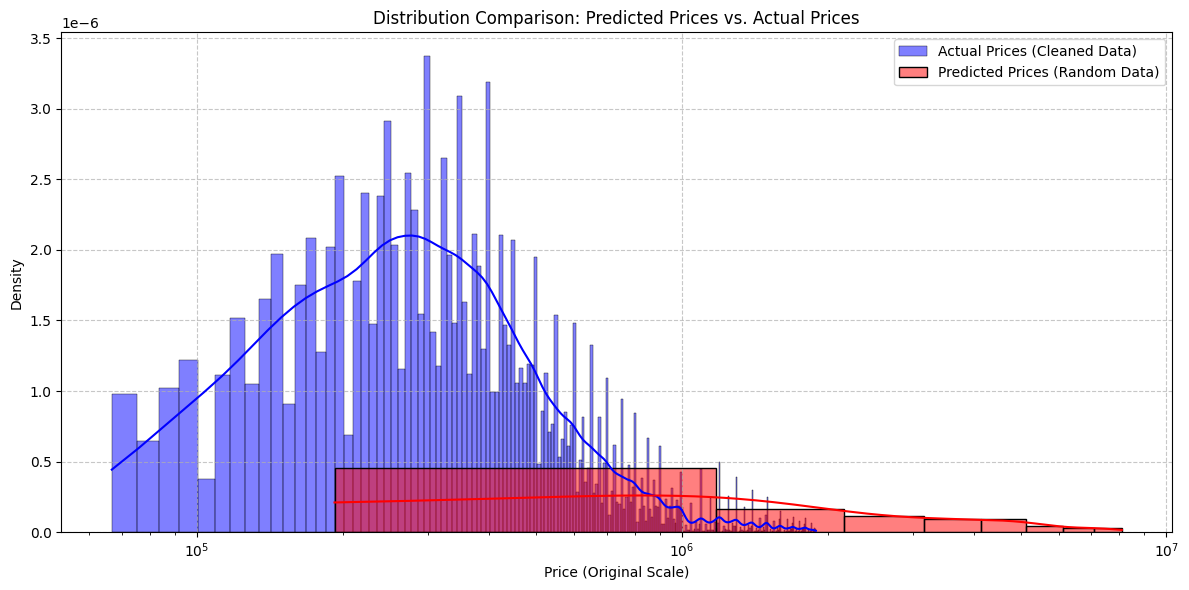

In [84]:
plt.figure(figsize=(12, 6))
sns.histplot(df_for_sale_cleaned_outliers['price'], color='blue', label='Actual Prices (Cleaned Data)', kde=True, stat='density', alpha=0.5)
sns.histplot(random_df_bed_bath['predicted_price'], color='red', label='Predicted Prices (Random Data)', kde=True, stat='density', alpha=0.5)
plt.title('Distribution Comparison: Predicted Prices vs. Actual Prices')
plt.xlabel('Price (Original Scale)')
plt.ylabel('Density')
plt.xscale('log') # Use log scale for better visualization if prices vary widely
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

**Line-by-line Explanation:**

1.  `plt.figure(figsize=(12, 6))`:
    *   **What it does:** This line creates a new figure (the canvas for your plot) and sets its size to 12 inches wide and 6 inches tall, providing a good aspect ratio for the comparison plot.

2.  `sns.histplot(df_for_sale_cleaned_outliers['price'], color='blue', label='Actual Prices (Cleaned Data)', kde=True, stat='density', alpha=0.5)`:
    *   **What it does:** This uses Seaborn's `histplot` to create a histogram for the actual prices from the `df_for_sale_cleaned_outliers` DataFrame.
        *   `color='blue'`: Sets the bars of this histogram to blue.
        *   `label='Actual Prices (Cleaned Data)'`: Provides a label for this data series, which will appear in the legend.
        *   `kde=True`: Overlays a Kernel Density Estimate (KDE) curve on the histogram, providing a smoothed representation of the price distribution.
        *   `stat='density'`: Normalizes the histogram so that the area under the bars sums to 1, making it comparable to a probability density function.
        *   `alpha=0.5`: Sets the transparency of the histogram to 50%, useful for comparing overlapping distributions.

3.  `sns.histplot(random_df_bed_bath['predicted_price'], color='red', label='Predicted Prices (Random Data)', kde=True, stat='density', alpha=0.5)`:
    *   **What it does:** This similarly creates a histogram for the `predicted_price` column from the `random_df_bed_bath` DataFrame, plotting it on the same axes as the actual prices for comparison.
        *   `color='red'`: Sets the bars of this histogram to red.
        *   `label='Predicted Prices (Random Data)'`: Provides a label for the legend.
        *   `kde=True`, `stat='density'`, `alpha=0.5`: Serve the same purpose as for the actual prices, ensuring consistent visualization.

4.  `plt.title('Distribution Comparison: Predicted Prices vs. Actual Prices')`:
    *   **What it does:** Sets the main title of the plot.

5.  `plt.xlabel('Price (Original Scale)')`:
    *   **What it does:** Sets the label for the x-axis, indicating that it represents prices on their original scale.

6.  `plt.ylabel('Density')`:
    *   **What it does:** Sets the label for the y-axis, indicating that it represents the density of the price distributions.

7.  `plt.xscale('log')`:
    *   **What it does:** Applies a logarithmic scale to the x-axis. This is particularly useful when price data has a wide range and is heavily skewed (e.g., many lower-priced homes and fewer very expensive homes), making the distribution clearer.

8.  `plt.legend()`:
    *   **What it does:** Displays the legend on the plot, using the `label` arguments provided in the `histplot` calls to identify which color corresponds to actual prices and which to predicted prices.

9.  `plt.grid(True, linestyle='--', alpha=0.7)`:
    *   **What it does:** Adds a grid to the plot for easier readability. `True` enables the grid, `linestyle='--'` uses dashed lines, and `alpha=0.7` sets transparency.

10. `plt.tight_layout()`:
    *   **What it does:** Automatically adjusts plot parameters for a tight layout, ensuring that labels, titles, and legends do not overlap or get cut off.

11. `plt.show()`:
    *   **What it does:** Displays the generated plot.

**What the output represents:**

The output is a histogram comparison plot showing two distributions:

*   **Blue bars/KDE curve:** Represents the distribution of `Actual Prices` from the cleaned `df_for_sale_cleaned_outliers` dataset. This shows the real-world price spread and density for the homes the model was trained on.
*   **Red bars/KDE curve:** Represents the distribution of `Predicted Prices` generated by `model_bed_bath` for the `random_df_bed_bath` data. This shows the range and concentration of prices that the model predicts for various hypothetical 'bed' and 'bath' combinations.

**Key Observations from the Plot:**

*   **Comparison of Peaks:** You can visually compare where the most frequent actual prices (blue peak) lie versus where the model predicts the most frequent prices (red peak).
*   **Spread and Range:** The plot immediately highlights whether the model's predicted price range is similar to the actual price range. Given the observed plot, the red distribution of predicted prices appears much narrower and lower in magnitude compared to the actual prices. The actual prices (blue) span a much wider range and have a higher density at lower price points.
*   **Model Limitations:** The significant difference between the two distributions suggests that `model_bed_bath` (which uses only 'bed' and 'bath') is likely underfitting the data. It struggles to capture the full complexity and variability of actual house prices, especially at higher price points, leading to a much more constrained and less accurate predicted distribution. This reinforces the earlier R-squared score of 0.12, indicating poor model performance.

### Predicted House Prices for Random Data (using 'bed' and 'bath' model)

In [85]:
display(random_df_bed_bath)

,bed,bath,predicted_price
0,10,8,3.966919e+06
1,6,4,7.525901e+05
2,5,8,2.949370e+06
3,4,8,2.779613e+06
4,3,5,8.996072e+05
...,...,...,...
95,10,9,5.664769e+06
96,1,1,1.921533e+05
97,6,4,7.525901e+05
98,6,6,1.534674e+06


**Line-by-line Explanation:**

1.  `display(random_df_bed_bath)`:
    *   **What it does:** This line uses the `display()` function (commonly used in Jupyter and Colab notebooks) to render the contents of the `random_df_bed_bath` DataFrame in a well-formatted, tabular output. This function is preferred over `print()` for DataFrames as it provides a richer, more readable representation.

**What the output represents:**

The output is a table displaying the entire `random_df_bed_bath` DataFrame. This DataFrame contains 100 rows, each representing a randomly generated house with specific values for 'bed' (number of bedrooms) and 'bath' (number of bathrooms), along with the `predicted_price` for that house as estimated by `model_bed_bath`.

For example:

*   **`bed`**: Shows the randomly assigned number of bedrooms for each entry.
*   **`bath`**: Shows the randomly assigned number of bathrooms for each entry.
*   **`predicted_price`**: Shows the price that the trained linear regression model (`model_bed_bath`) predicted for each corresponding 'bed' and 'bath' combination, after inverse-transforming from the log scale.

This output allows for a direct inspection of the model's predictions for a diverse set of synthetic house configurations. It helps confirm that the predictions are on the expected scale and provides specific examples of how the model values different combinations of bedrooms and bathrooms.

### Visualization of Predicted House Prices for Random Data (using 'bed' and 'bath' model)

This scatter plot shows the predicted house prices for the randomly generated combinations of 'bed' and 'bath'. The color intensity indicates the predicted price, allowing us to see how the model values different configurations.

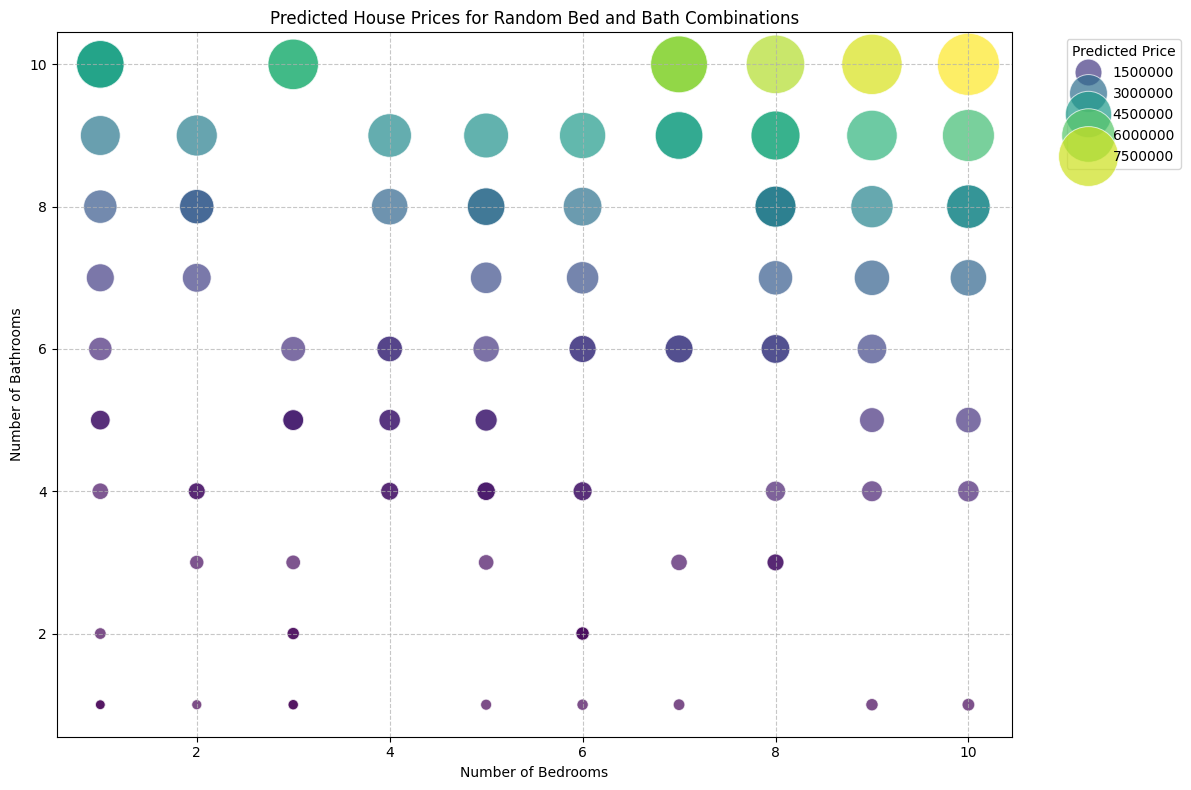

In [86]:
plt.figure(figsize=(12, 8))
sns.scatterplot(
    x='bed',
    y='bath',
    hue='predicted_price',
    size='predicted_price', # Use size to show magnitude as well
    sizes=(50, 2000), # Adjust size range as needed
    palette='viridis', # Choose a color palette
    data=random_df_bed_bath,
    alpha=0.7
)
plt.title('Predicted House Prices for Random Bed and Bath Combinations')
plt.xlabel('Number of Bedrooms')
plt.ylabel('Number of Bathrooms')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(title='Predicted Price', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Line-by-line Explanation:**

1.  `plt.figure(figsize=(12, 8))`:
    *   This line creates a new figure (the canvas for your plot) and sets its size to 12 inches wide and 8 inches tall. This helps in making the plot clear and readable.

2.  `sns.scatterplot(...)`:
    *   This is the core function call from the Seaborn library that creates a scatter plot.
    *   `x='bed'`: Specifies that the 'bed' column from the `random_df_bed_bath` DataFrame will be mapped to the x-axis, representing the number of bedrooms.
    *   `y='bath'`: Specifies that the 'bath' column will be mapped to the y-axis, representing the number of bathrooms.
    *   `hue='predicted_price'`: This is a crucial argument. It colors the data points based on their 'predicted_price'. Points with similar predicted prices will have similar colors, helping to visualize price clusters.
    *   `size='predicted_price'`: This argument makes the size of each data point (marker) proportional to its 'predicted_price'. Higher predicted prices will result in larger markers, adding another visual dimension to the plot.
    *   `sizes=(50, 2000)`: Sets the minimum and maximum size for the markers, ensuring they are neither too small to see nor too large to overlap excessively. In this case, sizes will range from 50 to 2000 units (often in square pixels).
    *   `palette='viridis'`: Chooses the 'viridis' color scheme for the `hue` mapping. This is a perceptually uniform colormap, which means changes in color are perceived consistently across the range.
    *   `data=random_df_bed_bath`: Specifies the DataFrame that contains the data for the plot.
    *   `alpha=0.7`: Sets the transparency of the markers to 70%. This is useful when points overlap, allowing you to see the density of points underneath.

3.  `plt.title('Predicted House Prices for Random Bed and Bath Combinations')`:
    *   Sets the main title of the scatter plot.

4.  `plt.xlabel('Number of Bedrooms')`:
    *   Sets the label for the x-axis.

5.  `plt.ylabel('Number of Bathrooms')`:
    *   Sets the label for the y-axis.

6.  `plt.grid(True, linestyle='--', alpha=0.7)`:
    *   Adds a grid to the plot for easier reading of values. `True` enables the grid, `linestyle='--'` sets it to dashed lines, and `alpha=0.7` makes it slightly transparent.

7.  `plt.legend(title='Predicted Price', bbox_to_anchor=(1.05, 1), loc='upper left')`:
    *   Displays a legend on the plot, explaining what the colors and sizes of the points represent.
    *   `title='Predicted Price'`: Sets the title for the legend.
    *   `bbox_to_anchor=(1.05, 1)` and `loc='upper left'`: These parameters position the legend outside the main plotting area, to the upper-right corner, preventing it from obscuring the data points.

8.  `plt.tight_layout()`:
    *   Automatically adjusts plot parameters for a tight layout, ensuring that labels, titles, and legends do not overlap or get cut off.

9.  `plt.show()`:
    *   Displays the generated plot. Without this line, the plot might not be rendered in some environments, or it might just return a Matplotlib object representation.

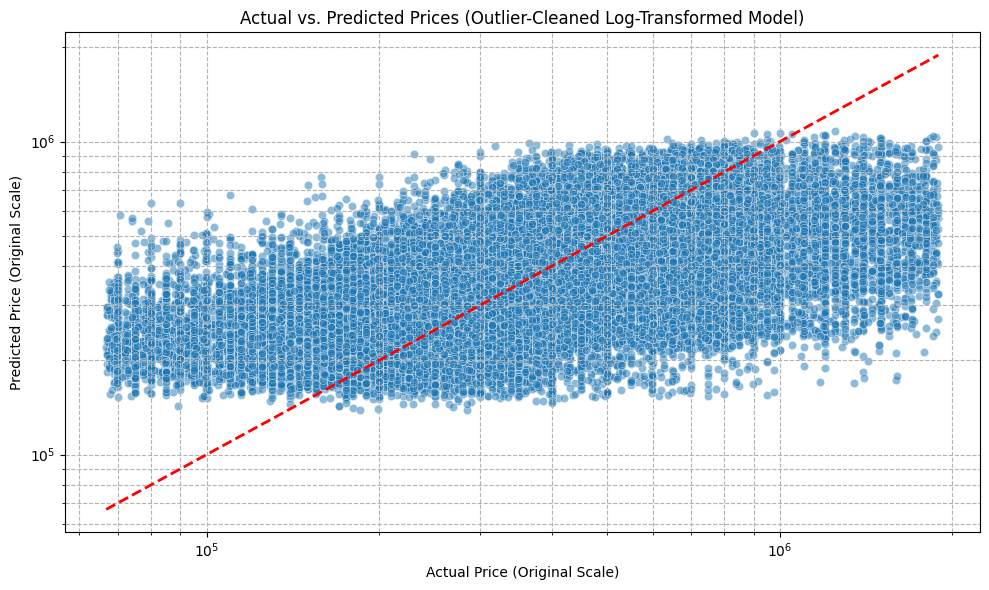

In [87]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_test_orig_scale_cleaned, y=y_pred_orig_scale_cleaned, alpha=0.5)
plt.plot([min(y_test_orig_scale_cleaned), max(y_test_orig_scale_cleaned)],
         [min(y_test_orig_scale_cleaned), max(y_test_orig_scale_cleaned)],
         color='red', linestyle='--', lw=2)
plt.title('Actual vs. Predicted Prices (Outlier-Cleaned Log-Transformed Model)')
plt.xlabel('Actual Price (Original Scale)')
plt.ylabel('Predicted Price (Original Scale)')
plt.xscale('log')
plt.yscale('log')
plt.grid(True, which="both", ls="--", c='0.7')
plt.tight_layout()
plt.show()


1.  `plt.figure(figsize=(10, 6))`:
    *   This line creates a new figure (the container for the plot) and sets its size to 10 inches wide and 6 inches tall for optimal viewing.

2.  `sns.scatterplot(x=y_test_orig_scale_cleaned, y=y_pred_orig_scale_cleaned, alpha=0.5)`:
    *   This generates a scatter plot using Seaborn.
    *   `x=y_test_orig_scale_cleaned`: The actual prices from the test set (on the original scale) are plotted on the x-axis.
    *   `y=y_pred_orig_scale_cleaned`: The predicted prices from the model (also on the original scale) are plotted on the y-axis.
    *   `alpha=0.5`: Sets the transparency of the points to 50%, which helps in visualizing dense areas where points overlap.

3.  `plt.plot([min(y_test_orig_scale_cleaned), max(y_test_orig_scale_cleaned)], [min(y_test_orig_scale_cleaned), max(y_test_orig_scale_cleaned)], color='red', linestyle='--', lw=2)`:
    *   This line draws a diagonal red dashed line on the plot. This line represents the ideal scenario where `Actual Price == Predicted Price`.
    *   `[min(y_test_orig_scale_cleaned), max(y_test_orig_scale_cleaned)]` is used to define the range for both x and y coordinates, ensuring the line spans the entire data range.
    *   `color='red'`, `linestyle='--'`, `lw=2`: Sets the line color to red, style to dashed, and line width to 2.

4.  `plt.title('Actual vs. Predicted Prices (Outlier-Cleaned Log-Transformed Model)')`:
    *   Sets the title of the plot.

5.  `plt.xlabel('Actual Price (Original Scale)')`:
    *   Sets the label for the x-axis.

6.  `plt.ylabel('Predicted Price (Original Scale)')`:
    *   Sets the label for the y-axis.

7.  `plt.xscale('log')`:
    *   Applies a logarithmic scale to the x-axis. This is particularly useful when the data spans several orders of magnitude, making patterns clearer and handling skewed distributions.

8.  `plt.yscale('log')`:
    *   Applies a logarithmic scale to the y-axis, similar to the x-axis, for better visualization of widely varying prices.

9.  `plt.grid(True, which="both", ls="--", c='0.7')`:
    *   Adds a grid to the plot for enhanced readability. `True` enables the grid, `which="both"` applies it to both major and minor ticks, `ls="--"` sets the line style to dashed, and `c='0.7'` sets the color to a light gray.

10. `plt.tight_layout()`:
    *   Automatically adjusts plot parameters for a tight layout, preventing labels and titles from overlapping.

11. `plt.show()`:
    *   Displays the generated plot.